# Corpus Exploration

Interactive notebook converted from `nlp_corpus_explore_modification.py`.

In [1]:
"""nlp_corpus_explore.py - Module 3 Script.

Author: Kevin Hennelly
Date: 2026-11

Purpose

  Perform exploratory analysis of a small, controlled text corpus.
  Demonstrate how structure emerges from token distributions,
  category comparisons, and co-occurrence patterns.

Analytical Questions

- What tokens dominate each category?
- How do categories differ in vocabulary?
- What words appear in similar contexts?
- What structure is visible before using any models?

Notes:
- This module focuses on exploratory analysis (EDA), not modeling.
- Results here prepare for later work with pipelines and embeddings.

Run from root project folder with:

  uv run python -m nlp.nlp_corpus_explore
"""

'nlp_corpus_explore.py - Module 3 Script.\n\nAuthor: Kevin Hennelly\nDate: 2026-11\n\nPurpose\n\n  Perform exploratory analysis of a small, controlled text corpus.\n  Demonstrate how structure emerges from token distributions,\n  category comparisons, and co-occurrence patterns.\n\nAnalytical Questions\n\n- What tokens dominate each category?\n- How do categories differ in vocabulary?\n- What words appear in similar contexts?\n- What structure is visible before using any models?\n\nNotes:\n- This module focuses on exploratory analysis (EDA), not modeling.\n- Results here prepare for later work with pipelines and embeddings.\n\nRun from root project folder with:\n\n  uv run python -m nlp.nlp_corpus_explore\n'

## Section 1. Setup and Imports

In [2]:
from collections import defaultdict
import logging
from pathlib import Path

from datafun_toolkit.logger import get_logger, log_header, log_path
import matplotlib.pyplot as plt
import polars as pl

print("Imports complete.")

Imports complete.


## Configure Logging

In [3]:
LOG: logging.Logger = get_logger("CI", level="DEBUG")

ROOT_PATH: Path = Path.cwd()
SCRIPTS_PATH: Path = ROOT_PATH / "scripts"

log_header(LOG, "MODULE 3: CORPUS EXPLORATION")
LOG.info("START script.....")

log_path(LOG, "ROOT_PATH", ROOT_PATH)
log_path(LOG, "SCRIPTS_PATH", SCRIPTS_PATH)

LOG.info("Logger configured.")

2026-11-05 10:37:39 | INFO | CI | === RUN START ===
2026-11-05 10:37:39 | INFO | CI | project=MODULE 3: CORPUS EXPLORATION
2026-11-05 10:37:39 | INFO | CI | repo_dir=nlp-03-text-exploration
2026-11-05 10:37:39 | INFO | CI | python=3.14.3
2026-11-05 10:37:39 | INFO | CI | os=Windows 11
2026-11-05 10:37:39 | INFO | CI | shell=powershell
2026-11-05 10:37:39 | INFO | CI | cwd=src\nlp
2026-11-05 10:37:39 | INFO | CI | github_actions=False
2026-11-05 10:37:39 | INFO | CI | START script.....
2026-11-05 10:37:39 | INFO | CI | ROOT_PATH = src\nlp
2026-11-05 10:37:39 | INFO | CI | SCRIPTS_PATH = src\nlp\scripts
2026-11-05 10:37:39 | INFO | CI | Logger configured.


## Section 2. Define Corpus (Labeled Text Documents)

In [4]:
# A corpus is a collection of documents.
# Each document includes a category and text.

corpus: list[dict[str, str]] = [
    # Dogs
    {"category": "dog", "text": "A dog barks loudly."},
    {"category": "dog", "text": "The puppy runs in the yard."},
    {"category": "dog", "text": "A canine wears a leash."},
    {"category": "dog", "text": "The kennel holds the dog."},
    {"category": "dog", "text": "The dog ran across the yard."},
    {"category": "dog", "text": "The puppy ran across the yard."},
    # Cats
    {"category": "cat", "text": "A cat sleeps quietly."},
    {"category": "cat", "text": "The kitten plays with yarn."},
    {"category": "cat", "text": "A feline purrs softly."},
    {"category": "cat", "text": "The cat has whiskers."},
    {"category": "cat", "text": "The cat slept near the window."},
    {"category": "cat", "text": "The kitten slept near the window."},
    # Cars
    {"category": "car", "text": "A car drives on the road."},
    {"category": "car", "text": "The sedan parks in the garage."},
    {"category": "car", "text": "A vehicle has four wheels."},
    {"category": "car", "text": "The car moves down the highway."},
    {"category": "car", "text": "The car stopped near the garage."},
    {"category": "car", "text": "The sedan stopped near the garage."},
    # Trucks
    {"category": "truck", "text": "A truck carries cargo."},
    {"category": "truck", "text": "The pickup pulls a trailer."},
    {"category": "truck", "text": "The engine powers the truck."},
    {"category": "truck", "text": "The truck hauls heavy loads."},
]

# Show results
print(f"Corpus contains {len(corpus)} documents.")

Corpus contains 22 documents.


## Section 3. Tokenize and Clean Text

In [5]:
# Tokenization splits text into word-like units.


# Define a function to tokenize text by lowercasing, splitting on whitespace,
# and stripping common punctuation. We also filter out very short tokens (length <= 2).
# This simple tokenizer is sufficient for our small, controlled corpus.
# Use the string strip() method to remove punctuation from the beginning and end of each token.
def tokenize(text: str) -> list[str]:
    """Tokenize the input text into a list of cleaned tokens."""
    tokens = text.lower().split()
    return [t.strip(".,:;!?()[]\"'") for t in tokens if len(t) > 2]


# Define a new empty list to hold the token records we will create.
records_list: list[dict[str, str]] = []

# Loop through each document, tokenize the text,
# and create a record for each token with its category and
# add it to our list of records.
for doc in corpus:
    # Call our function to tokenize the text of the current document.
    tokens = tokenize(doc["text"])
    # Loop through each token produced by the tokenizer and
    # create a record that includes the category of the document and the token itself.
    # Append this record to our list of records.
    for token in tokens:
        records_list.append({"category": doc["category"], "token": token})

# Create a Polars DataFrame from the list of token records for easier analysis.
token_df: pl.DataFrame = pl.DataFrame(records_list)

# Show results
print("Tokenization complete.")
print(token_df.head(10))

Tokenization complete.
shape: (10, 2)
┌──────────┬────────┐
│ category ┆ token  │
│ ---      ┆ ---    │
│ str      ┆ str    │
╞══════════╪════════╡
│ dog      ┆ dog    │
│ dog      ┆ barks  │
│ dog      ┆ loudly │
│ dog      ┆ the    │
│ dog      ┆ puppy  │
│ dog      ┆ runs   │
│ dog      ┆ the    │
│ dog      ┆ yard   │
│ dog      ┆ canine │
│ dog      ┆ wears  │
└──────────┴────────┘


## Section 4. Compute Global Token Frequencies

In [6]:
# Frequency distribution = how often each token appears.

# Create a DataFrame that groups the tokens by their text and
# counts how many times each token appears across the entire corpus.
global_freq_df: pl.DataFrame = (
    token_df.group_by("token").len().sort("len", descending=True)
)

# Show results
print("Top global tokens:")
print(global_freq_df.head(10))

Top global tokens:
shape: (10, 2)
┌────────┬─────┐
│ token  ┆ len │
│ ---    ┆ --- │
│ str    ┆ u64 │
╞════════╪═════╡
│ the    ┆ 27  │
│ near   ┆ 4   │
│ dog    ┆ 3   │
│ truck  ┆ 3   │
│ cat    ┆ 3   │
│ car    ┆ 3   │
│ garage ┆ 3   │
│ yard   ┆ 3   │
│ across ┆ 2   │
│ window ┆ 2   │
└────────┴─────┘


## Section 5. Compute Token Frequencies by Category

In [7]:
# Compare token usage across categories.

# Create a new DataFrame that groups the tokens by both their category and text,
# counts how many times each token appears within each category,
# and sorts the results first by category and then by frequency in descending order.
# This shows which tokens are most common within each category.
category_freq_df: pl.DataFrame = (
    token_df.group_by(["category", "token"])
    .len()
    .sort(["category", "len"], descending=True)
)

# Technical modification: Calculate relative token frequencies as a percentage
category_freq_df = category_freq_df.with_columns(
    (pl.col("len") / pl.col("len").sum().over("category") * 100)
    .round(2)
    .alias("percentage")
)

# Show results
print("Top tokens by category:")
print(category_freq_df.head(12))

Top tokens by category:
shape: (12, 4)
┌──────────┬─────────┬─────┬────────────┐
│ category ┆ token   ┆ len ┆ percentage │
│ ---      ┆ ---     ┆ --- ┆ ---        │
│ str      ┆ str     ┆ u64 ┆ f64        │
╞══════════╪═════════╪═════╪════════════╡
│ truck    ┆ the     ┆ 4   ┆ 23.53      │
│ truck    ┆ truck   ┆ 3   ┆ 17.65      │
│ truck    ┆ carries ┆ 1   ┆ 5.88       │
│ truck    ┆ hauls   ┆ 1   ┆ 5.88       │
│ truck    ┆ pulls   ┆ 1   ┆ 5.88       │
│ …        ┆ …       ┆ …   ┆ …          │
│ truck    ┆ heavy   ┆ 1   ┆ 5.88       │
│ truck    ┆ engine  ┆ 1   ┆ 5.88       │
│ truck    ┆ pickup  ┆ 1   ┆ 5.88       │
│ truck    ┆ trailer ┆ 1   ┆ 5.88       │
│ truck    ┆ powers  ┆ 1   ┆ 5.88       │
└──────────┴─────────┴─────┴────────────┘


## Section 6. Identify Top Tokens per Category

In [8]:
# Show top tokens per category.


# Define a new empty dictionary to store the top tokens for each category.
top_per_category_dict: dict[str, list[str]] = {}

# Loop through each unique category in the token DataFrame,
# filter the category frequency DataFrame to get the top 5 tokens for that category,
# and store the list of top tokens in the dictionary.
# Also, print the top tokens for each category.
for category in token_df["category"].unique().to_list():
    subset_df = category_freq_df.filter(pl.col("category") == category).head(5)
    top_tokens_list = subset_df["token"].to_list()
    top_per_category_dict[category] = top_tokens_list

    # Show results for this category
    print(f"{category.upper()} top tokens: {top_tokens_list}")

CAR top tokens: ['the', 'garage', 'car', 'sedan', 'stopped']
CAT top tokens: ['the', 'cat', 'window', 'near', 'kitten']
DOG top tokens: ['the', 'dog', 'yard', 'ran', 'across']
TRUCK top tokens: ['the', 'truck', 'carries', 'hauls', 'pulls']


## Section 7. Analyze Co-occurrence (Context Windows)

In [9]:
# Co-occurrence examines which tokens appear near each other.

# Define how many tokens on each side of a target token we include as context.
# A window size of 2 means:
#   - up to 2 tokens before the target token
#   - up to 2 tokens after the target token
# The target token itself is not included in its context list.
WINDOW_SIZE: int = 2

# Define a new empty dictionary to store the co-occurrence information.
# The keys will be target tokens,
# and the values will be lists of context tokens that appear near the target token.
co_occurrence_dict: dict[str, list[str]] = defaultdict(list)

# Loop through each document in the corpus, tokenize the text,
# and for each token, determine its context tokens based on the defined window size.
for doc in corpus:
    tokens = tokenize(doc["text"])
    for i, token in enumerate(tokens):
        start = max(0, i - WINDOW_SIZE)
        end = min(len(tokens), i + WINDOW_SIZE + 1)
        context = tokens[start:end]
        for ctx in context:
            if ctx != token:
                co_occurrence_dict[token].append(ctx)

# Show results
for target in ["dog", "cat", "car", "truck"]:
    print(f"\nContext for '{target}':")
    print(co_occurrence_dict[target][:10])


Context for 'dog':
['barks', 'loudly', 'holds', 'the', 'the', 'ran', 'across']

Context for 'cat':
['sleeps', 'quietly', 'the', 'has', 'whiskers', 'the', 'slept', 'near']

Context for 'car':
['drives', 'the', 'the', 'moves', 'down', 'the', 'stopped', 'near']

Context for 'truck':
['carries', 'cargo', 'powers', 'the', 'the', 'hauls', 'heavy']


## Section 8. Create Bigrams (Local Word Pairs) and Compute Frequencies

In [10]:
# Bigrams combine each word with the next word in the text.
# This helps us capture local structure: how words are used together,
# not just which words appear individually.

# Bigrams capture pairs of consecutive tokens.

# Define a new empty list to hold the bigram tuples we will create.
bigrams_list: list[tuple[str, str]] = []

# Loop through each document in the corpus, tokenize the text,
# and create bigrams by pairing each token with the next token in the list.
for doc in corpus:
    tokens = tokenize(doc["text"])
    for i in range(len(tokens) - 1):
        bigrams_list.append((tokens[i], tokens[i + 1]))

# Create a DataFrame from the list of bigram tuples,
# where each bigram is represented as a single string with the two tokens separated by a space.
bigram_df: pl.DataFrame = pl.DataFrame(
    {"bigram": [f"{a} {b}" for a, b in bigrams_list]}
)

# Create a new DataFrame that groups the bigrams by their text
# and counts how many times each bigram appears,
# then sorts the results by frequency in descending order.
bigram_freq_df: pl.DataFrame = (
    bigram_df.group_by("bigram").len().sort("len", descending=True)
)

# Show results
print("Top bigrams:")
print(bigram_freq_df.head(10))

Top bigrams:
shape: (10, 2)
┌──────────────┬─────┐
│ bigram       ┆ len │
│ ---          ┆ --- │
│ str          ┆ u64 │
╞══════════════╪═════╡
│ near the     ┆ 4   │
│ the garage   ┆ 3   │
│ the yard     ┆ 3   │
│ the sedan    ┆ 2   │
│ the cat      ┆ 2   │
│ slept near   ┆ 2   │
│ stopped near ┆ 2   │
│ the truck    ┆ 2   │
│ the dog      ┆ 2   │
│ ran across   ┆ 2   │
└──────────────┴─────┘


## Section 9. Visualize Token Frequencies

IMPORTANT: Close chart window to continue execution.


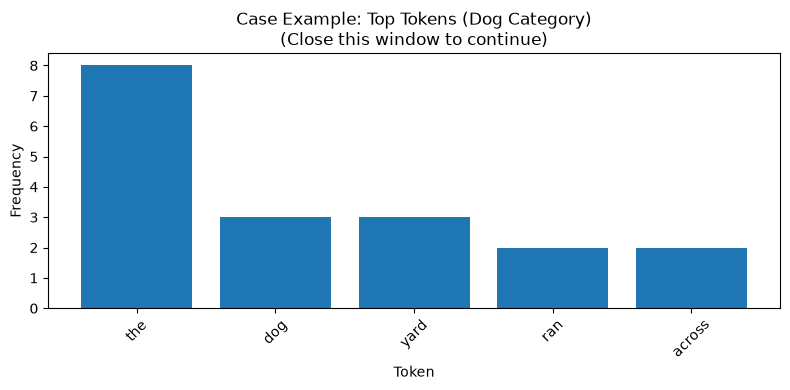

In [11]:
print("IMPORTANT: Close chart window to continue execution.")

# Define a new DataFrame that filters the category frequency DataFrame
# to get the top 5 tokens for the "dog" category.
dog_df = category_freq_df.filter(pl.col("category") == "dog").head(5)

# Create a figure that is 8 inches wide and 4 inches tall
plt.figure(figsize=(8, 4))

# Add a bar chart to the figure using the tokens as the x-axis and their frequencies as the y-axis.
plt.bar(dog_df["token"], dog_df["len"])

# Define the x-axis tick parameters to rotate the labels by 45 degrees for better readability.
# The gca() function gets the current axes of the plot, and tick_params() is used to set the rotation of the x-axis labels.
ax = plt.gca()
ax.tick_params(axis="x", labelrotation=45)

# Set the title and labels for the axes of the plot.
plt.title("Case Example: Top Tokens (Dog Category)\n(Close this window to continue)")
plt.xlabel("Token")
plt.ylabel("Frequency")

# Adjust the layout of the plot to prevent overlap and ensure everything fits well.
plt.tight_layout()

# Display the plot on the screen.
# The execution of the script will pause until the plot window is closed.
plt.show()

## Section 10. Interpret Results and Identify Patterns

In [12]:
print("\nCASE GENERAL OBSERVATIONS:")

print("- Tokens cluster by category (dog, cat, car, truck).")
print("- Words that appear in similar contexts behave similarly.")
print("- Co-occurrence reveals contextual relationships between words.")
print("- Bigrams capture local structure beyond single tokens.")
print("- Patterns emerge before any machine learning is applied.")

print("\nYOURNAME SPECIFIC OBSERVATIONS:")
print("TODO")


CASE GENERAL OBSERVATIONS:
- Tokens cluster by category (dog, cat, car, truck).
- Words that appear in similar contexts behave similarly.
- Co-occurrence reveals contextual relationships between words.
- Bigrams capture local structure beyond single tokens.
- Patterns emerge before any machine learning is applied.

YOURNAME SPECIFIC OBSERVATIONS:
TODO


In [13]:
LOG.info("========================")
LOG.info("Pipeline executed successfully!")
LOG.info("========================")
LOG.info("END main()")

2026-11-05 10:37:39 | INFO | CI | ========================
2026-11-05 10:37:39 | INFO | CI | Pipeline executed successfully!
2026-11-05 10:37:39 | INFO | CI | ========================
2026-11-05 10:37:39 | INFO | CI | END main()
